
Joint robustness (% of SOWs satisfying both criteria):
strategy_id  joint_robustness
         S1              0.15
         S2             29.64
         S3             65.06
         S4             40.23
         S5              7.20

Baseline annual irrigation = 1167.0 mm yr^-1
20% irrigation-reduction threshold = 933.6 mm yr^-1
Baseline annual yield = 9.46 ton acre^-1 yr^-1
20% yield-loss threshold = 7.56 ton acre^-1 yr^-1

Historical contextual ranges (2000-2020):
Imperial County yield = 6.06-8.15 ton acre^-1 yr^-1
DWR modeled net irrigation (ETaw) = 1005.8-1905.0 mm yr^-1


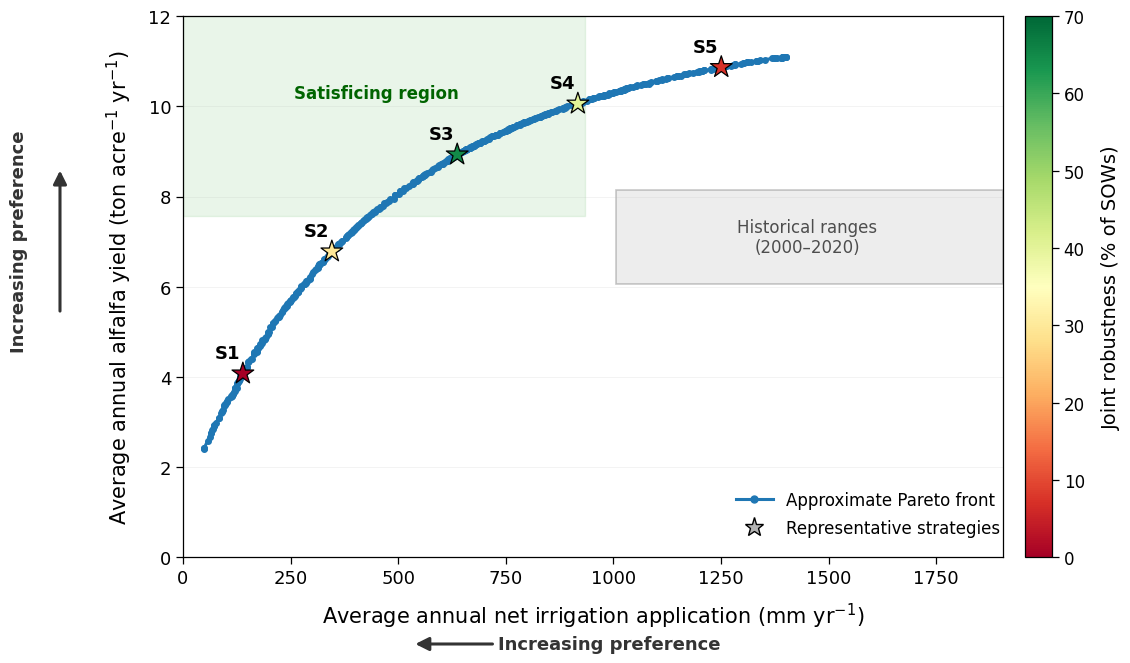

In [6]:
# Figure 2: Annualized Pareto front with representative strategies,
# robustness, historical reference ranges, and satisficing region

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

base_dir = Path("NSGA2_K300_P100_G100_S101")
results_dir = Path("Strategies_Performance")

final_df = pd.read_csv(base_dir / "final_pareto_archive_from_all_population.csv")
selected_df = pd.read_csv(results_dir / "selected_5_representative_strategies.csv")
performance_df = pd.read_csv(
    results_dir / "K10000" / "strategy_performance_across_futures_k10000_seed54321.csv"
)

performance_df = performance_df[performance_df["status"] == "success"].copy()

strategy_order = ["S1", "S2", "S3", "S4", "S5"]
n_production_years = 5.0
MG_HA_PER_TON_ACRE = 2.2417

for df in [final_df, selected_df]:
    df["irr_annual"] = df["irr_mean"] / n_production_years
    df["yld_annual"] = df["yld_mean"] / n_production_years / MG_HA_PER_TON_ACRE

final_df = final_df.sort_values("irr_annual").copy()

selected_df["strategy_id"] = pd.Categorical(
    selected_df["strategy_id"], categories=strategy_order, ordered=True
)
selected_df = selected_df.sort_values("strategy_id").copy()

baseline_irr_total = 5834.781
baseline_yld_total_Mg_ha = 105.978
retention_fraction = 0.80

irrigation_threshold_total = baseline_irr_total * retention_fraction
yield_threshold_total = baseline_yld_total_Mg_ha * retention_fraction

performance_df["meets_yield"] = (
    performance_df["cumulative_yield_Mg_ha"] >= yield_threshold_total
)
performance_df["meets_irrigation"] = (
    performance_df["cumulative_irrigation_mm"] <= irrigation_threshold_total
)
performance_df["meets_all"] = (
    performance_df["meets_yield"] & performance_df["meets_irrigation"]
)

robustness = (
    performance_df.groupby("strategy_id")["meets_all"]
    .mean()
    .mul(100)
    .reindex(strategy_order)
    .rename("joint_robustness")
    .reset_index()
)

selected_df["strategy_id"] = selected_df["strategy_id"].astype(str)
selected_df = selected_df.merge(robustness, on="strategy_id", how="left")

print("\nJoint robustness (% of SOWs satisfying both criteria):")
print(selected_df[["strategy_id", "joint_robustness"]].to_string(index=False))

baseline_irr_annual = baseline_irr_total / n_production_years
baseline_yld_annual = baseline_yld_total_Mg_ha / n_production_years / MG_HA_PER_TON_ACRE

irrigation_threshold = baseline_irr_annual * retention_fraction
yield_threshold = baseline_yld_annual * retention_fraction

print(f"\nBaseline annual irrigation = {baseline_irr_annual:.1f} mm yr^-1")
print(f"20% irrigation-reduction threshold = {irrigation_threshold:.1f} mm yr^-1")
print(f"Baseline annual yield = {baseline_yld_annual:.2f} ton acre^-1 yr^-1")
print(f"20% yield-loss threshold = {yield_threshold:.2f} ton acre^-1 yr^-1")

historical_yield_min, historical_yield_max = 6.06, 8.15
historical_net_irr_min, historical_net_irr_max = 1005.8, 1905.0

print("\nHistorical contextual ranges (2000-2020):")
print(
    f"Imperial County yield = {historical_yield_min:.2f}-"
    f"{historical_yield_max:.2f} ton acre^-1 yr^-1"
)
print(
    f"DWR modeled net irrigation (ETaw) = {historical_net_irr_min:.1f}-"
    f"{historical_net_irr_max:.1f} mm yr^-1"
)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 13,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "axes.linewidth": 0.9,
    "xtick.major.width": 0.9,
    "ytick.major.width": 0.9,
    "xtick.major.size": 5,
    "ytick.major.size": 5,
})

fig, ax = plt.subplots(figsize=(11.5, 6.8))

x_min, x_max = 0, historical_net_irr_max
y_min, tick_interval = 0, 2

y_data_max = max(
    final_df["yld_annual"].max(),
    selected_df["yld_annual"].max(),
    historical_yield_max,
    yield_threshold,
)
y_max = np.ceil(y_data_max / tick_interval) * tick_interval

ax.add_patch(Rectangle(
    (historical_net_irr_min, historical_yield_min),
    historical_net_irr_max - historical_net_irr_min,
    historical_yield_max - historical_yield_min,
    facecolor="0.80", alpha=0.35, edgecolor="0.40",
    linewidth=1.2, zorder=0,
))

ax.fill_between(
    [x_min, irrigation_threshold], yield_threshold, y_max,
    color="tab:green", alpha=0.10, zorder=0,
)

ax.text(
    450, 10.3, "Satisficing region",
    fontsize=12, fontweight="semibold",
    color="darkgreen", ha="center", va="center",
    zorder=3,
)

ax.text(
    1450, 7.1, "Historical ranges\n(2000–2020)",
    fontsize=12,
    color="0.30", ha="center", va="center",
    zorder=3,
)

ax.plot(
    final_df["irr_annual"], final_df["yld_annual"],
    marker="o", color="tab:blue", linewidth=2.2,
    markersize=4, zorder=2,
)

strategy_scatter = ax.scatter(
    selected_df["irr_annual"], selected_df["yld_annual"],
    c=selected_df["joint_robustness"],
    cmap=plt.cm.RdYlGn, norm=Normalize(vmin=0, vmax=70),
    marker="*", s=270, edgecolor="black", linewidth=0.9, zorder=4,
)

cbar = fig.colorbar(strategy_scatter, ax=ax, pad=0.025, fraction=0.045)
cbar.set_label("Joint robustness (% of SOWs)", fontsize=14, labelpad=12)
cbar.set_ticks(np.arange(0, 71, 10))
cbar.ax.tick_params(labelsize=12)

for _, row in selected_df.iterrows():
    ax.annotate(
        row["strategy_id"],
        xy=(row["irr_annual"], row["yld_annual"]),
        xytext=(-2, 8), textcoords="offset points",
        fontsize=13, fontweight="bold",
        ha="right", va="bottom", zorder=5,
    )

ax.annotate(
    "Increasing preference",
    xy=(0.28, -0.16), xytext=(0.52, -0.16),
    xycoords="axes fraction", textcoords="axes fraction",
    arrowprops=dict(
        arrowstyle="-|>", linewidth=2.2,
        color="0.20", mutation_scale=20,
    ),
    fontsize=13, fontweight="semibold", color="0.20",
    ha="center", va="center",
    annotation_clip=False, clip_on=False, zorder=6,
)

ax.annotate(
    "",
    xy=(-0.15, 0.72), xytext=(-0.15, 0.45),
    xycoords="axes fraction", textcoords="axes fraction",
    arrowprops=dict(
        arrowstyle="-|>", linewidth=2.2,
        color="0.20", mutation_scale=20,
    ),
    annotation_clip=False, clip_on=False, zorder=6,
)

ax.text(
    -0.20, 0.585, "Increasing preference",
    transform=ax.transAxes, fontsize=13,
    fontweight="semibold", color="0.20",
    rotation=90, ha="center", va="center",
    clip_on=False, zorder=6,
)

ax.set_xlabel(
    r"Average annual net irrigation application (mm yr$^{-1}$)",
    fontsize=15, labelpad=10,
)
ax.set_ylabel(
    r"Average annual alfalfa yield (ton acre$^{-1}$ yr$^{-1}$)",
    fontsize=15, labelpad=10,
)

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_xticks(np.arange(0, 1751, 250))
ax.set_yticks(np.arange(y_min, y_max + tick_interval, tick_interval))
ax.tick_params(axis="both", which="major", labelsize=13)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.9)

ax.grid(axis="y", linewidth=0.5, alpha=0.20)
ax.grid(axis="x", visible=False)
ax.tick_params(direction="out", top=False, right=False)

legend_handles = [
    Line2D([0], [0], color="tab:blue", marker="o",
           linewidth=2.2, markersize=5),
    Line2D([0], [0], marker="*", linestyle="None",
           markerfacecolor="0.70", markeredgecolor="black", markersize=14),
]

legend_labels = [
    "Approximate Pareto front",
    "Representative strategies",
]

ax.legend(
    handles=legend_handles, labels=legend_labels,
    frameon=False, loc="lower right",
    bbox_to_anchor=(1.005, 0.025),
    borderaxespad=0.0, labelspacing=0.60,
    handletextpad=0.8, handlelength=2.2, fontsize=12,
)

fig.tight_layout()
plt.show()

In [2]:
# TABLE 3: Representative strategies — decision levers and performance outcomes

import pandas as pd
from pathlib import Path
results_dir = Path("Strategies_Performance")
diagnostics_dir = results_dir / "Irrigation_Diagnostics"
selected = pd.read_csv(results_dir / "selected_5_representative_strategies.csv")
irr_summary = pd.read_csv(diagnostics_dir / "irrigation_summary_by_strategy.csv")
seasonal_summary = pd.read_csv(diagnostics_dir / "seasonal_irrigation_summary.csv")
strategy_order = ["S1", "S2", "S3", "S4", "S5"]
def sort_by_strategy(df):
    col = "Strategy" if "Strategy" in df.columns else "strategy_id"
    if col not in df.columns:
        raise ValueError("Missing strategy identifier column")
    df = df[df[col].isin(strategy_order)].copy()
    df[col] = pd.Categorical(df[col], categories=strategy_order, ordered=True)
    df = df.sort_values(col).reset_index(drop=True)
    if len(df) != 5:
        raise ValueError(f"Expected 5 strategies, found {len(df)}")
    return df
selected = sort_by_strategy(selected)
irr_summary = sort_by_strategy(irr_summary)
seasonal_summary = sort_by_strategy(seasonal_summary)
pretty_names = {
    "planting_doy": "Planting day (DOY)",
    "yield_cutoff": "Yield cutoff (Mg ha⁻¹)",
    "establishment_days": "Establishment duration (days)",
    "MAD": "MAD (–)",
    "refill_target": "Refill target (fraction of TAW)",
    "survival_fraction": "Survival threshold (fraction of TAW)",
    "max_irrigation": "Maximum irrigation (mm day⁻¹)",
    "initial_smt": "Initial soil-moisture target (fraction of TAW)",
    "min_infiltration": "Minimum infiltration (mm day⁻¹)",
    "pre_harvest_no_irrigation_days": "Pre-harvest buffer (days)",
    "post_cutting_buffer_days": "Post-cutting buffer (days)",
    "DI_establishment": "DI establishment (–)",
    "DI_winter": "DI winter (–)",
    "DI_spring": "DI spring (–)",
    "DI_summer": "DI summer (–)",
    "DI_fall": "DI fall (–)",
}
decision_cols = list(pretty_names)
missing = [col for col in decision_cols if col not in selected.columns]
if missing:
    raise ValueError(f"Missing decision columns: {missing}")
table = selected[decision_cols].T.copy()
table.columns = [f"Strategy {i}" for i in range(1, 6)]
table.index = [pretty_names[col] for col in decision_cols]
table.index.name = "Decision lever / outcome"
def find_column(df, candidates, label):
    for col in candidates:
        if col in df.columns:
            return col
    raise ValueError(f"Missing {label}. Available columns: {list(df.columns)}")
def mean_sd_integer(means, sds):
    def fmt(value):
        value = float(value)
        return "<1" if 0 < value < 1 else f"{value:.0f}"
    return [f"{fmt(m)} ± {fmt(s)}" for m, s in zip(means, sds)]
def mean_sd_one_decimal(means, sds):
    return [f"{float(m):.1f} ± {float(s):.1f}" for m, s in zip(means, sds)]
irrigation_columns = {
    "Annual irrigation": (
        irr_summary,
        ["annual_irrigation_mm_mean", "Irrigation_mean_mm_yr",
         "irrigation_mean_mm_yr", "Annual_Irrigation_mean_mm_yr"],
        ["annual_irrigation_mm_sd", "Irrigation_SD_mm_yr",
         "irrigation_sd_mm_yr", "Annual_Irrigation_SD_mm_yr"],
    ),
    "Routine irrigation": (
        irr_summary,
        ["annual_routine_mm_mean", "Routine_mean_mm_yr",
         "routine_mean_mm_yr", "Annual_Routine_Irrigation_mean_mm_yr"],
        ["annual_routine_mm_sd", "Routine_SD_mm_yr",
         "routine_sd_mm_yr", "Annual_Routine_Irrigation_SD_mm_yr"],
    ),
    "Emergency irrigation": (
        irr_summary,
        ["annual_emergency_mm_mean", "Emergency_mean_mm_yr",
         "emergency_mean_mm_yr", "Annual_Emergency_Irrigation_mean_mm_yr"],
        ["annual_emergency_mm_sd", "Emergency_SD_mm_yr",
         "emergency_sd_mm_yr", "Annual_Emergency_Irrigation_SD_mm_yr"],
    ),
}
for season in ["Establishment", "Winter", "Spring", "Summer", "Fall"]:
    lower = season.lower()
    irrigation_columns[f"{season} irrigation"] = (
        seasonal_summary,
        [f"{season}_mean_mm_yr", f"{lower}_mean_mm_yr"],
        [f"{season}_SD_mm_yr", f"{lower}_SD_mm_yr", f"{lower}_sd_mm_yr"],
    )
irrigation_means = {}
for label, (df, mean_candidates, sd_candidates) in irrigation_columns.items():
    mean_col = find_column(df, mean_candidates, f"{label} mean")
    sd_col = find_column(df, sd_candidates, f"{label} SD")
    means = df[mean_col].astype(float).to_numpy()
    sds = df[sd_col].astype(float).to_numpy()
    irrigation_means[label] = means
    table.loc[f"{label} (mm yr⁻¹)"] = mean_sd_integer(means, sds)
yield_mean = irr_summary["annual_yield_Mg_ha_mean"].astype(float).to_numpy()
yield_sd = irr_summary["annual_yield_Mg_ha_sd"].astype(float).to_numpy()
conversion_factor = 0.44609
table.loc["Annual yield (Mg ha⁻¹ yr⁻¹)"] = mean_sd_one_decimal(yield_mean, yield_sd)
table.loc["Annual yield (ton acre⁻¹ yr⁻¹)"] = mean_sd_one_decimal(
    yield_mean * conversion_factor,
    yield_sd * conversion_factor,
)
integer_rows = [
    "Planting day (DOY)",
    "Establishment duration (days)",
    "Pre-harvest buffer (days)",
    "Post-cutting buffer (days)",
]
outcome_rows = [
    f"{label} (mm yr⁻¹)" for label in irrigation_columns
] + [
    "Annual yield (Mg ha⁻¹ yr⁻¹)",
    "Annual yield (ton acre⁻¹ yr⁻¹)",
]
formatted_table = table.astype(object).copy()
for row in formatted_table.index:
    if row in outcome_rows:
        continue
    decimals = 0 if row in integer_rows else 2
    formatted_table.loc[row] = [
        f"{float(value):.{decimals}f}" for value in table.loc[row]
    ]
print("\nTABLE 3. REPRESENTATIVE STRATEGIES — DECISION LEVERS AND PERFORMANCE OUTCOMES")
print(formatted_table.to_string())

seasonal_sum = sum(
    irrigation_means[f"{season} irrigation"]
    for season in ["Establishment", "Winter", "Spring", "Summer", "Fall"]
)
total_mean = irrigation_means["Annual irrigation"]
seasonal_difference = seasonal_sum - total_mean


TABLE 3. REPRESENTATIVE STRATEGIES — DECISION LEVERS AND PERFORMANCE OUTCOMES
                                               Strategy 1  Strategy 2  Strategy 3  Strategy 4  Strategy 5
Decision lever / outcome                                                                                 
Planting day (DOY)                                    247         245         245         246         247
Yield cutoff (Mg ha⁻¹)                               0.13        0.13        0.18        0.17        0.12
Establishment duration (days)                         172         181         174         179         182
MAD (–)                                              0.80        0.80        0.80        0.70        0.60
Refill target (fraction of TAW)                      0.52        0.66        0.96        0.96        0.94
Survival threshold (fraction of TAW)                 0.05        0.11        0.14        0.02        0.10
Maximum irrigation (mm day⁻¹)                       16.59       16.74    

Baseline annual yield = 9.46 ton acre^-1 yr^-1
Yield threshold = 7.56 ton acre^-1 yr^-1
Baseline annual irrigation = 1167.0 mm yr^-1
Irrigation threshold = 933.6 mm yr^-1


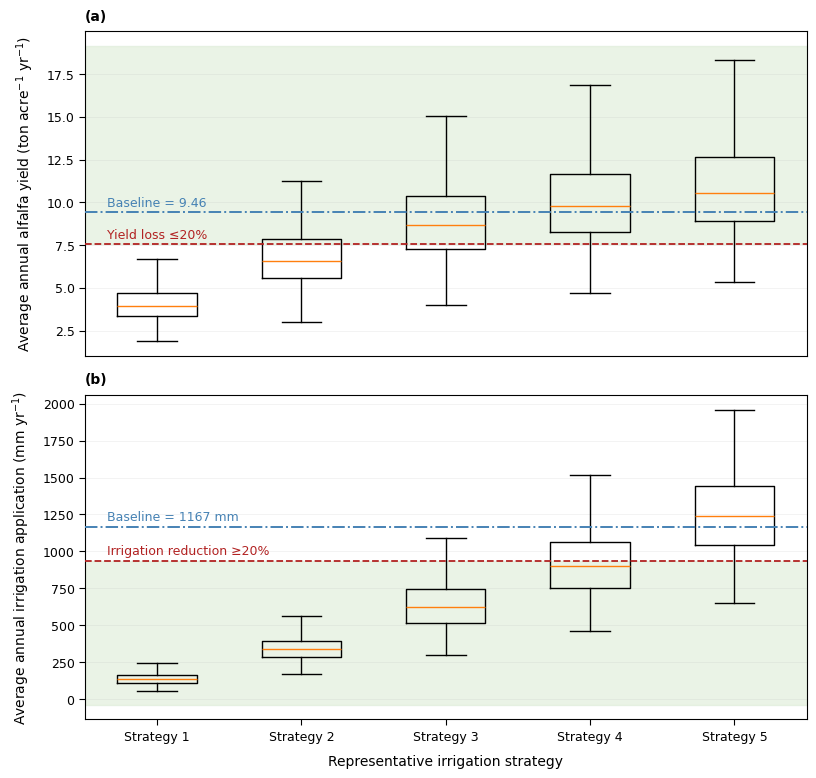

In [3]:
# Figure 3: Performance of representative irrigation strategies across 10,000 independent uncertain SOWs

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
file = Path(
    "Strategies_Performance/K10000/"
    "strategy_performance_across_futures_k10000_seed54321.csv"
)
df = pd.read_csv(file)
df = df[df["status"] == "success"].copy()
strategy_order = ["S1", "S2", "S3", "S4", "S5"]
plot_labels = [f"Strategy {i}" for i in range(1, 6)]

df["strategy_id"] = pd.Categorical(
    df["strategy_id"], categories=strategy_order, ordered=True
)
df = df.sort_values("strategy_id")
baseline_yield_5yr = 105.978
baseline_irrigation_5yr = 5834.781
yield_loss_allowed_pct = 20
irrigation_reduction_pct = 20
MG_HA_TO_TON_ACRE = 0.44609
yield_threshold_5yr = baseline_yield_5yr * (1 - yield_loss_allowed_pct / 100)
irrigation_threshold_5yr = baseline_irrigation_5yr * (1 - irrigation_reduction_pct / 100)
df["yield_annual_ton_acre"] = df["cumulative_yield_Mg_ha"] / 5.0 * MG_HA_TO_TON_ACRE
df["irrigation_annual"] = df["cumulative_irrigation_mm"] / 5.0
yield_threshold_annual_ton_acre = yield_threshold_5yr / 5.0 * MG_HA_TO_TON_ACRE
irrigation_threshold_annual = irrigation_threshold_5yr / 5.0
baseline_yield_annual_ton_acre = baseline_yield_5yr / 5.0 * MG_HA_TO_TON_ACRE
baseline_irrigation_annual = baseline_irrigation_5yr / 5.0
print(f"Baseline annual yield = {baseline_yield_annual_ton_acre:.2f} ton acre^-1 yr^-1")
print(f"Yield threshold = {yield_threshold_annual_ton_acre:.2f} ton acre^-1 yr^-1")
print(f"Baseline annual irrigation = {baseline_irrigation_annual:.1f} mm yr^-1")
print(f"Irrigation threshold = {irrigation_threshold_annual:.1f} mm yr^-1")
yield_data = [
    df.loc[df["strategy_id"] == s, "yield_annual_ton_acre"]
    for s in strategy_order
]
irrigation_data = [
    df.loc[df["strategy_id"] == s, "irrigation_annual"]
    for s in strategy_order
]
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})
fig, axes = plt.subplots(
    2, 1, figsize=(8.8, 8.0),
    sharex=True, gridspec_kw={"hspace": 0.12}
)
axes[0].boxplot(yield_data, tick_labels=plot_labels, showfliers=False, widths=0.55)
_, yield_ymax = axes[0].get_ylim()

axes[0].axhspan(
    yield_threshold_annual_ton_acre, yield_ymax,
    color="#d9ead3", alpha=0.55, zorder=0
)
axes[0].axhline(
    yield_threshold_annual_ton_acre,
    linestyle="--", linewidth=1.3, color="firebrick", zorder=3
)
axes[0].text(
    0.65, yield_threshold_annual_ton_acre + 0.15,
    "Yield loss ≤20%", fontsize=9, color="firebrick",
    ha="left", va="bottom"
)

axes[0].axhline(
    baseline_yield_annual_ton_acre,
    linestyle="-.", linewidth=1.4, color="steelblue", zorder=3
)
axes[0].text(
    0.65, baseline_yield_annual_ton_acre + 0.15,
    f"Baseline = {baseline_yield_annual_ton_acre:.2f}",
    fontsize=9, color="steelblue", ha="left", va="bottom"
)
axes[0].set_ylabel(
    r"Average annual alfalfa yield (ton acre$^{-1}$ yr$^{-1}$)",
    fontsize=10, labelpad=8
)

axes[1].boxplot(
    irrigation_data, tick_labels=plot_labels,
    showfliers=False, widths=0.55
)
irr_ymin, _ = axes[1].get_ylim()

axes[1].axhspan(
    irr_ymin, irrigation_threshold_annual,
    color="#d9ead3", alpha=0.55, zorder=0
)
axes[1].axhline(
    irrigation_threshold_annual,
    linestyle="--", linewidth=1.3, color="firebrick", zorder=3
)
axes[1].text(
    0.65, irrigation_threshold_annual + 25,
    "Irrigation reduction ≥20%", fontsize=9,
    color="firebrick", ha="left", va="bottom"
)
axes[1].axhline(
    baseline_irrigation_annual,
    linestyle="-.", linewidth=1.4, color="steelblue", zorder=3
)
axes[1].text(
    0.65, baseline_irrigation_annual + 25,
    f"Baseline = {baseline_irrigation_annual:.0f} mm",
    fontsize=9, color="steelblue", ha="left", va="bottom"
)
axes[1].set_ylabel(
    r"Average annual irrigation application (mm yr$^{-1}$)",
    fontsize=10, labelpad=8
)
for i, ax in enumerate(axes):
    ax.text(
        0.0, 1.025, f"({chr(97 + i)})",
        transform=ax.transAxes, fontsize=10,
        fontweight="bold", ha="left", va="bottom", clip_on=False
    )
axes[0].tick_params(axis="x", which="both", bottom=False, labelbottom=False)
axes[1].tick_params(
    axis="x", which="both", bottom=True,
    labelbottom=True, labelsize=9, rotation=0
)
axes[1].set_xticks(range(1, 6))
axes[1].set_xticklabels(plot_labels, fontsize=9)
axes[1].set_xlabel(
    "Representative irrigation strategy", fontsize=10, labelpad=8
)
for ax in axes:
    ax.grid(axis="y", linewidth=0.5, alpha=0.20)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
    ax.tick_params(direction="out", top=False, right=False, labelsize=9)

fig.subplots_adjust(
    left=0.16, right=0.98, top=0.96,
    bottom=0.10, hspace=0.12
)
plt.show()


PARAMETERS DISPLAYED IN FIGURE 4
                                Irrigation_mean_ST  Yield_mean_ST  Overall_mean_ST
Crop coefficient scale                       0.595          0.456            0.525
Depletion fraction, p                        0.381          0.063            0.222
Water productivity scale                     0.000          0.422            0.211
Yield-response curvature scale               0.000          0.059            0.029
Weather window                               0.022          0.016            0.019
Root depth                                   0.009          0.003            0.006
Available water capacity                     0.006          0.002            0.004


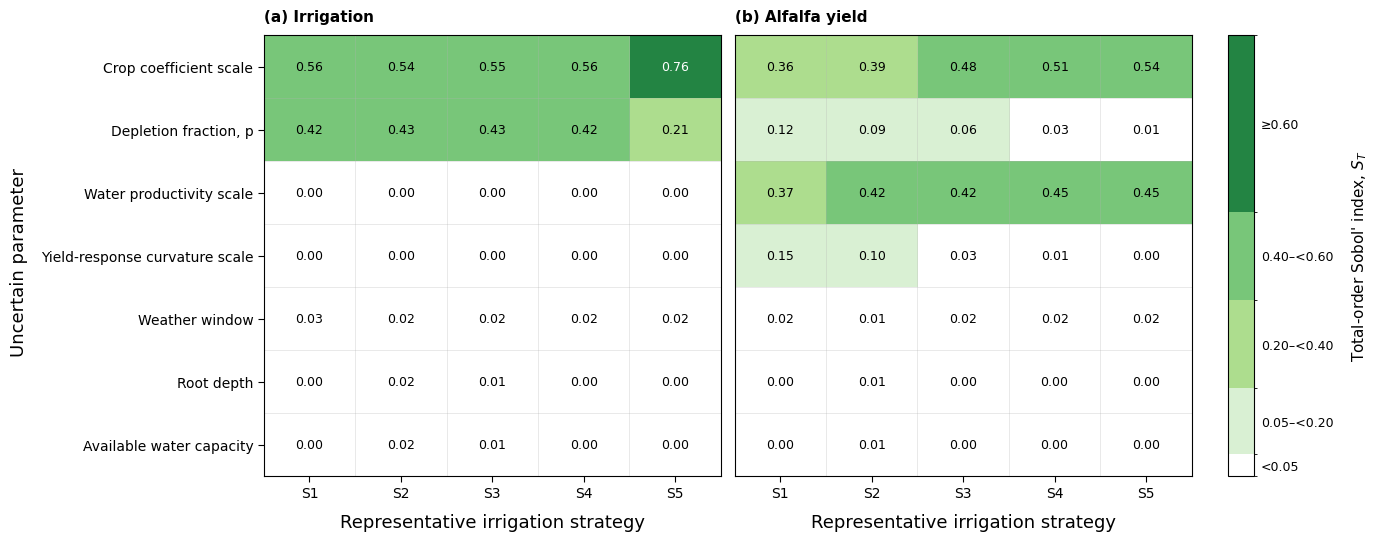

In [4]:
# Figure 4: Global sensitivity of irrigation and yield N = 1024

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
SOBOL_DIR = Path("Sobol_Results/Sobol_Results_N1024")
N, SEED = 1024, 2026
TOP_PER_OBJECTIVE = 5
STRATEGY_ORDER = ["S1", "S2", "S3", "S4", "S5"]
PARAMETER_LABELS = {
    "kc_scale": "Crop coefficient scale",
    "temperature_dormancy_threshold": "Dormancy temperature threshold",
    "p_depletion": "Depletion fraction, p",
    "wp_scale": "Water productivity scale",
    "Kmitsch_scale": "Yield-response curvature scale",
    "climate_window_u": "Weather window",
    "AWC_raw": "Available water capacity",
    "root_depth_mm": "Root depth",
    "K_sat": "Saturated hydraulic conductivity",
    "theta_s_raw": "Saturated water content",
    "theta_r_raw": "Residual water content",
    "n": "Van Genuchten n",
    "pwp_raw": "Permanent wilting point",
}
SENSITIVITY_BOUNDS = [0.00, 0.05, 0.20, 0.40, 0.60, 1.0001]
SENSITIVITY_COLORS = ["white", "#d9f0d3", "#addd8e", "#78c679", "#238443"]
COLORBAR_LABELS = ["<0.05", "0.05–<0.20", "0.20–<0.40", "0.40–<0.60", "≥0.60"]
COLORBAR_TICKS = [0.025, 0.125, 0.300, 0.500, 0.800]
cmap = ListedColormap(SENSITIVITY_COLORS)
norm = BoundaryNorm(SENSITIVITY_BOUNDS, cmap.N)
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})
def load_total_order_indices(objective):
    if objective not in {"irr", "yld"}:
        raise ValueError("Objective must be 'irr' or 'yld'")

    data = {}
    for strategy in STRATEGY_ORDER:
        file = (
            SOBOL_DIR / f"Sobol_{strategy}"
            / f"sobol_Si_{strategy}_{objective}_N{N}_seed{SEED}.csv"
        )
        if not file.exists():
            raise FileNotFoundError(file)

        df = pd.read_csv(file)
        missing = {"param", "ST"} - set(df.columns)
        if missing:
            raise ValueError(f"{file.name}: missing columns {sorted(missing)}")

        data[strategy] = (
            df[["param", "ST"]]
            .drop_duplicates(subset="param")
            .set_index("param")["ST"]
            .astype(float)
        )
    return pd.DataFrame(data).clip(lower=0.0)
def select_common_parameters(irrigation_df, yield_df):
    irrigation_mean = irrigation_df[STRATEGY_ORDER].mean(axis=1)
    yield_mean = yield_df[STRATEGY_ORDER].mean(axis=1)

    top_irrigation = irrigation_mean.nlargest(TOP_PER_OBJECTIVE).index
    top_yield = yield_mean.nlargest(TOP_PER_OBJECTIVE).index
    common_parameters = top_irrigation.union(top_yield)

    ranking = pd.DataFrame({
        "Irrigation_mean_ST": irrigation_mean.loc[common_parameters],
        "Yield_mean_ST": yield_mean.loc[common_parameters],
    })
    ranking["Overall_mean_ST"] = ranking.mean(axis=1)
    ranking = ranking.sort_values("Overall_mean_ST", ascending=False)
    return ranking.index, ranking
def add_heatmap_panel(ax, plot_df, panel_label, outcome_label):
    matrix = plot_df.to_numpy(dtype=float)
    n_parameters, n_strategies = matrix.shape

    heatmap = ax.imshow(
        matrix, aspect="auto", interpolation="nearest",
        cmap=cmap, norm=norm
    )
    ax.set_xticks(np.arange(n_strategies))
    ax.set_xticklabels(STRATEGY_ORDER)
    ax.set_xlabel("Representative irrigation strategy", fontsize=13, labelpad=9)
    ax.set_yticks(np.arange(n_parameters))
    ax.set_yticklabels([PARAMETER_LABELS.get(p, p) for p in plot_df.index])

    ax.text(
        0.0, 1.025, f"{panel_label} {outcome_label}",
        transform=ax.transAxes, fontsize=11, fontweight="bold",
        ha="left", va="bottom", clip_on=False
    )
    for i in range(n_parameters):
        for j in range(n_strategies):
            value = matrix[i, j]
            ax.text(
                j, i, f"{value:.2f}",
                ha="center", va="center", fontsize=9,
                color="white" if value >= 0.60 else "black"
            )
    ax.set_xticks(np.arange(-0.5, n_strategies, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_parameters, 1), minor=True)
    ax.grid(which="minor", linewidth=0.45, color="0.70", alpha=0.45)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.tick_params(direction="out", top=False, right=False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
    return heatmap
irrigation_st = load_total_order_indices("irr")
yield_st = load_total_order_indices("yld")
common_parameter_order, combined_parameter_ranking = select_common_parameters(
    irrigation_st, yield_st
)
irrigation_plot_data = irrigation_st.loc[common_parameter_order, STRATEGY_ORDER].copy()
yield_plot_data = yield_st.loc[common_parameter_order, STRATEGY_ORDER].copy()
print("\nPARAMETERS DISPLAYED IN FIGURE 4")
ranking_print = combined_parameter_ranking.copy()
ranking_print.index = [PARAMETER_LABELS.get(p, p) for p in ranking_print.index]
print(ranking_print.round(3).to_string())
figure_height = max(5.8, 0.72 * len(common_parameter_order))
fig, axes = plt.subplots(1, 2, figsize=(14.5, figure_height), sharey=True)
irrigation_heatmap = add_heatmap_panel(
    axes[0], irrigation_plot_data, "(a)", "Irrigation"
)
add_heatmap_panel(
    axes[1], yield_plot_data, "(b)", "Alfalfa yield"
)
axes[0].tick_params(axis="y", which="major", labelleft=True)
axes[1].tick_params(axis="y", which="major", labelleft=False, left=False)
axes[0].set_ylabel("")
axes[1].set_ylabel("")
fig.supylabel("Uncertain parameter", fontsize=13, x=0.025, y=0.52)
fig.subplots_adjust(
    left=0.20, right=0.84, bottom=0.15,
    top=0.91, wspace=0.03
)
cbar_ax = fig.add_axes([0.865, 0.15, 0.018, 0.76])
colorbar = fig.colorbar(
    irrigation_heatmap,
    cax=cbar_ax,
    boundaries=SENSITIVITY_BOUNDS,
    ticks=COLORBAR_TICKS,
    spacing="proportional"
)
colorbar.set_label(
    r"Total-order Sobol' index, $S_T$",
    fontsize=11,
    labelpad=12
)
colorbar.ax.set_yticklabels(COLORBAR_LABELS, fontsize=9)
colorbar.ax.tick_params(width=0.8, length=0, pad=5)

plt.show()

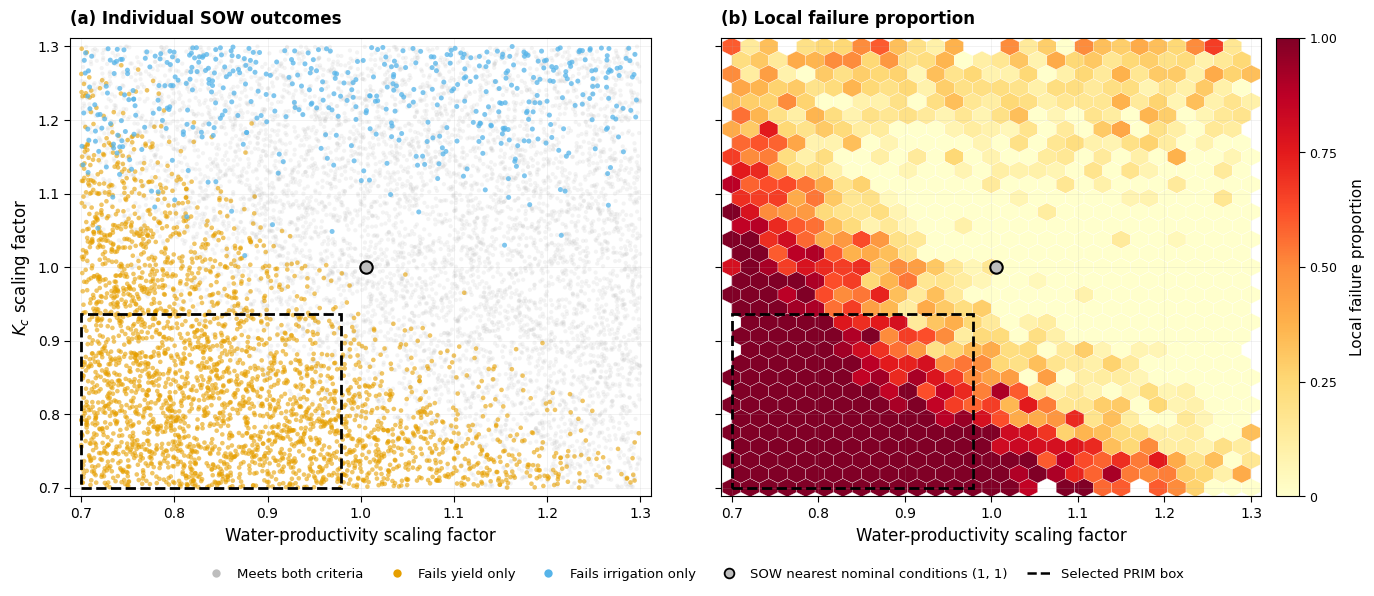

In [5]:
# Figure 5: PRIM scenario discovery for Strategy 3

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

results_dir = Path("PRIM_Results")
strategy_data = pd.read_csv(results_dir / "prim_sow_outcomes_S3.csv")
limits = pd.read_csv(results_dir / "prim_selected_box_limits_S3.csv")
x_parameter, y_parameter = "wp_scale", "kc_scale"
x_limits = limits.set_index("parameter").loc[x_parameter]
y_limits = limits.set_index("parameter").loc[y_parameter]
x_box_min, x_box_max = x_limits["box_min"], x_limits["box_max"]
y_box_min, y_box_max = y_limits["box_min"], y_limits["box_max"]
x_min, x_max = strategy_data[x_parameter].min(), strategy_data[x_parameter].max()
y_min, y_max = strategy_data[y_parameter].min(), strategy_data[y_parameter].max()
x_padding = 0.02 * (x_max - x_min)
y_padding = 0.02 * (y_max - y_min)
colors = {
    "Meets both criteria": "#BDBDBD",
    "Fails yield only": "#E69F00",
    "Fails irrigation only": "#56B4E9",
    "Fails both criteria": "#D55E00",
}
reference_idx = (
    (strategy_data[x_parameter] - 1.0) ** 2
    + (strategy_data[y_parameter] - 1.0) ** 2
).idxmin()
reference = strategy_data.loc[reference_idx]
reference_x = reference[x_parameter]
reference_y = reference[y_parameter]
reference_type = reference["failure_type"]
reference_color = colors[reference_type]
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9.5,
    "axes.linewidth": 0.8,
})
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.2), sharex=True, sharey=True)
ax1, ax2 = axes
# (a) Individual SOW outcomes
plot_settings = [
    ("Meets both criteria", 9, 0.18, 1),
    ("Fails yield only", 11, 0.60, 2),
    ("Fails irrigation only", 13, 0.75, 3),
    ("Fails both criteria", 16, 0.85, 4),
]
for category, size, alpha, zorder in plot_settings:
    subset = strategy_data.loc[strategy_data["failure_type"].eq(category)]
    ax1.scatter(
        subset[x_parameter], subset[y_parameter],
        s=size, alpha=alpha, color=colors[category],
        edgecolors="black" if category == "Fails both criteria" else "none",
        linewidths=0.2 if category == "Fails both criteria" else 0,
        rasterized=True, zorder=zorder,
    )
ax1.set_title("(a) Individual SOW outcomes",
              fontsize=12, fontweight="bold", loc="left", pad=10)

# (b) Local failure proportion
hexbin = ax2.hexbin(
    strategy_data[x_parameter],
    strategy_data[y_parameter],
    C=strategy_data["combined_failure"].astype(int),
    reduce_C_function=np.mean,
    gridsize=28,
    mincnt=3,
    extent=(x_min, x_max, y_min, y_max),
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    linewidths=0.20,
    edgecolors="white",
    rasterized=True,
    zorder=1,
)
ax2.set_title("(b) Local failure proportion",
              fontsize=12, fontweight="bold", loc="left", pad=10)

# Selected PRIM box and reference SOW
for ax in axes:
    ax.add_patch(plt.Rectangle(
        (x_box_min, y_box_min),
        x_box_max - x_box_min,
        y_box_max - y_box_min,
        fill=False, edgecolor="black",
        linestyle="--", linewidth=2.0, zorder=10,
    ))

    ax.scatter(
        [reference_x], [reference_y],
        s=80, alpha=1.0, facecolor=reference_color,
        edgecolor="black", linewidth=1.5, zorder=20,
    )

    ax.set_xlabel("Water-productivity scaling factor")
    ax.set_xlim(x_min - x_padding, x_max + x_padding)
    ax.set_ylim(y_min - y_padding, y_max + y_padding)
    ax.grid(alpha=0.18, linewidth=0.6)

ax1.set_ylabel(r"$K_c$ scaling factor")
colorbar = fig.colorbar(hexbin, ax=ax2, pad=0.025, fraction=0.046)
colorbar.set_label("Local failure proportion", fontsize=11, labelpad=9)
colorbar.set_ticks([0, 0.25, 0.50, 0.75, 1.0])
colorbar.set_ticklabels(["0", "0.25", "0.50", "0.75", "1.00"])
colorbar.ax.tick_params(labelsize=9)
legend_handles = [
    Line2D([0], [0], marker="o", linestyle="none", markersize=6,
           markerfacecolor=colors["Meets both criteria"],
           markeredgecolor="none", label="Meets both criteria"),
    Line2D([0], [0], marker="o", linestyle="none", markersize=6,
           markerfacecolor=colors["Fails yield only"],
           markeredgecolor="none", label="Fails yield only"),
    Line2D([0], [0], marker="o", linestyle="none", markersize=6,
           markerfacecolor=colors["Fails irrigation only"],
           markeredgecolor="none", label="Fails irrigation only"),
    Line2D([0], [0], marker="o", linestyle="none", markersize=7,
           markerfacecolor="#BDBDBD", markeredgecolor="black",
           markeredgewidth=1.3,
           label="SOW nearest nominal conditions (1, 1)"),
    Line2D([0], [0], linestyle="--", linewidth=1.8,
           color="black", label="Selected PRIM box"),
]
fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.50, 0.015),
    ncol=5,
    frameon=False,
    fontsize=9.5,
    columnspacing=1.5,
    handletextpad=0.6,
)
fig.subplots_adjust(
    left=0.07, right=0.92,
    bottom=0.17, top=0.91, wspace=0.12,
)
plt.show()